# Week 13: Formal Principles of Autonomous Agents & Structural Tool Constraints (Demo)

Instructor demonstration notebook. All cells are meant to be run top to bottom.
Section 1 builds a ReAct agent loop from scratch with a deterministic mock LLM.
Section 2 implements grammar-constrained decoding (logit-level masking) on a real GPT-2 model.
Section 3 compares three memory architectures: Buffer, Summary, and TF-IDF Retrieval memory.
Section 4 wires three mock agents into a sequential pipeline and a rule-based router (Slides 34–37).

No LangChain, CrewAI, AutoGen, or Outlines. Every mechanism is built from `torch` / `transformers` primitives so the underlying math stays visible.


In [1]:
# Required libraries (versions used when this notebook was authored)
# torch>=2.0.0
# transformers>=4.40.0
# numpy>=1.24.0
# matplotlib>=3.7.0
# seaborn>=0.12.0
# scikit-learn>=1.3.0
# tiktoken>=0.5.0
# Uncomment to install:
# !pip install -q torch transformers numpy matplotlib seaborn scikit-learn tiktoken


In [2]:
# ═══════════════════════════════════════════
# SECTION 0: Setup — Imports, Device, Seed
# Theory: An agent loop is just Python control flow around an LLM call. We keep the
#   LLM calls in Section 1 mocked (deterministic) so the ReAct loop itself is the star.
#   Section 2 switches to a real causal LM because logit masking only makes sense on
#   real logits from a real vocabulary.
# What this cell does: Import libraries, set seeds, detect device.
# ═══════════════════════════════════════════

import re
import json
import random
from collections import namedtuple

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns
import tiktoken

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = 'mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

TOKENIZER_FOR_COUNTING = tiktoken.get_encoding('cl100k_base')


def count_tokens(text: str) -> int:
    # Approximate token count using the cl100k_base BPE (same family as GPT-4).
    return len(TOKENIZER_FOR_COUNTING.encode(text))


Device: mps


## Section 1 — Building a ReAct Agent from Scratch

We formalize the agent as: `state -> LLM -> (thought, action) -> environment -> observation -> new state`.
The augmented state contains the entire history. With that definition it is Markov; truncating it can make the model's observation incomplete.


In [3]:
# ═══════════════════════════════════════════
# SECTION 1.1: Tool Functions (the Agent's Actuators)
# Theory: Tools are just Python functions with a string-in, string-out signature. The
#   LLM never calls these directly — it emits text naming a tool + input, and our
#   dispatcher (Section 1.3) calls the real function.
# What this cell does: Define 3 deterministic mock tools.
# ═══════════════════════════════════════════

_WIKI_KB = {
    'population of tokyo': 'Tokyo (Greater Tokyo Area) has a population of approximately 14,000,000.',
    'population of bangkok': 'Bangkok has a population of approximately 10,700,000.',
    'capital of thailand': 'The capital of Thailand is Bangkok.',
}


def search_wikipedia(query: str) -> str:
    key = query.strip().lower()
    for k, v in _WIKI_KB.items():
        if k in key or key in k:
            return v
    return f"No article found for '{query}'."


def calculator(expr: str) -> str:
    # Restrict eval to arithmetic characters only — this is a teaching tool, not a sandboxed executor.
    if not re.fullmatch(r'[0-9\.\+\-\*\/\(\)\s]+', expr):
        return f"Error: '{expr}' contains disallowed characters."
    try:
        return str(eval(expr, {'__builtins__': {}}, {}))
    except Exception as e:
        return f'Error: {e}'


def get_weather(location: str) -> str:
    fake_weather = {'bangkok': '33C, humid', 'tokyo': '18C, clear'}
    return fake_weather.get(location.strip().lower(), f"No weather data for '{location}'.")


TOOLS = {
    'search_wikipedia': search_wikipedia,
    'calculator': calculator,
    'get_weather': get_weather,
}
print('Registered tools:', list(TOOLS.keys()))


Registered tools: ['search_wikipedia', 'calculator', 'get_weather']


In [4]:
# ═══════════════════════════════════════════
# SECTION 1.2: The ReAct Prompt Template & Action Parser
# Theory: The LLM is instructed to always emit Thought/Action, then STOP and wait for
#   an Observation. This is the exact protocol from Yao et al. (2023).
# What this cell does: Define the system prompt string and a regex parser.
# ═══════════════════════════════════════════

REACT_SYSTEM_PROMPT = (
    "You are an agent that solves tasks step by step.\n"
    "At each turn, output exactly:\n"
    "Thought: <your reasoning>\n"
    "Action: <tool_name>[<argument>]\n"
    "Then stop. Wait for an Observation before continuing.\n"
    "When you know the final answer, output:\n"
    "Thought: <your reasoning>\n"
    "Action: finish[<final answer>]\n\n"
    "Available tools: search_wikipedia[query], calculator[expression], get_weather[location]\n"
)


Action = namedtuple('Action', ['name', 'argument'])   # same names as Slide 11: action.name, action.argument


def parse_action(llm_output: str):
    # Extract the Action line from a ReAct-formatted LLM output as Action(name, argument).
    # Returns None if the format could not be parsed.
    match = re.search(r'Action:\s*(\w+)\[(.*?)\]', llm_output, re.DOTALL)
    if match is None:
        return None
    return Action(name=match.group(1), argument=match.group(2))


# Quick sanity check
_test_thought = 'Thought: I need Tokyo population.\nAction: search_wikipedia[population of Tokyo]'
print(parse_action(_test_thought))


Action(name='search_wikipedia', argument='population of Tokyo')


In [5]:
# ═══════════════════════════════════════════
# SECTION 1.3: The Mock LLM and the ReAct Execution Loop
# Theory: An agent is a `while` loop, not a single forward pass — that loop is what
#   turns a static LLM into a dynamic controller (Slide 11). We mock `llm_generate`
#   with a scripted dict keyed by step number so today's demo is 100% reproducible;
#   in production this function would call a real model.
# What this cell does: Implements react_agent(query, tools, max_steps) — the Slide 11
#   pseudocode with the same names, plus error handling for malformed or unknown actions.
# ═══════════════════════════════════════════

_SCRIPTED_STEPS = {
    0: 'Thought: I need the population of Tokyo first.\nAction: search_wikipedia[population of Tokyo]',
    1: 'Thought: Now I divide the population by 1000.\nAction: calculator[14000000 / 1000]',
    2: 'Thought: I have the final number.\nAction: finish[The population of Tokyo divided by 1000 is 14000.0]',
}


def mock_llm_response(prompt: str, step: int) -> str:
    return _SCRIPTED_STEPS.get(step, 'Thought: I am not sure what to do.\nAction: finish[I could not solve this task.]')


def build_prompt(query: str, history: list) -> str:
    # Rebuild the FULL prompt from scratch every step. This is the augmented
    # state s_t = (q, h_1:t-1) from Slide 10. Nothing is dropped.
    parts = [REACT_SYSTEM_PROMPT, f'Question: {query}']
    for h in history:
        parts.append(h['thought_action'])
        parts.append(f"Observation: {h['observation']}")
    return '\n'.join(parts)


def react_agent(query: str, tools: dict, llm_generate=mock_llm_response, max_steps: int = 5, verbose: bool = True):
    history = []
    for step in range(max_steps):
        prompt = build_prompt(query, history)  # full-history augmented state
        llm_output = llm_generate(prompt, step)  # LLM decides: 'Thought: ...\nAction: name[argument]'
        action = parse_action(llm_output)        # Slide 11 writes these two lines as: thought, action = llm_generate(prompt)

        if action is None:
            observation = "Error: could not parse an Action. Format must be 'Action: name[argument]'."
            history.append({'thought_action': llm_output, 'observation': observation})
            if verbose:
                print(f'--- Step {step} ---\n{llm_output}\nObservation: {observation}\n')
            continue

        if action.name == 'finish':
            if verbose:
                print(f'--- Step {step} (FINAL) ---\n{llm_output}\n')
            return action.argument, history   # Done! (history too, so we can print the trace)

        if action.name not in tools:
            observation = f"Error: tool '{action.name}' does not exist. Available: {list(tools.keys())}"
        else:
            observation = tools[action.name](action.argument)

        history.append({'thought_action': llm_output, 'observation': observation})
        if verbose:
            print(f'--- Step {step} ---\n{llm_output}\nObservation: {observation}\n')

    return 'Max steps reached — agent failed.', history


In [6]:
# ═══════════════════════════════════════════
# SECTION 1.4: Execution Demo
# What this cell does: Run the loop on "What is the population of Tokyo divided by 1000?"
# ═══════════════════════════════════════════

answer, trace = react_agent('What is the population of Tokyo divided by 1000?', TOOLS)
print('FINAL ANSWER:', answer)


--- Step 0 ---
Thought: I need the population of Tokyo first.
Action: search_wikipedia[population of Tokyo]
Observation: Tokyo (Greater Tokyo Area) has a population of approximately 14,000,000.

--- Step 1 ---
Thought: Now I divide the population by 1000.
Action: calculator[14000000 / 1000]
Observation: 14000.0

--- Step 2 (FINAL) ---
Thought: I have the final number.
Action: finish[The population of Tokyo divided by 1000 is 14000.0]

FINAL ANSWER: The population of Tokyo divided by 1000 is 14000.0


Cumulative tokens per step: [100, 141, 173]


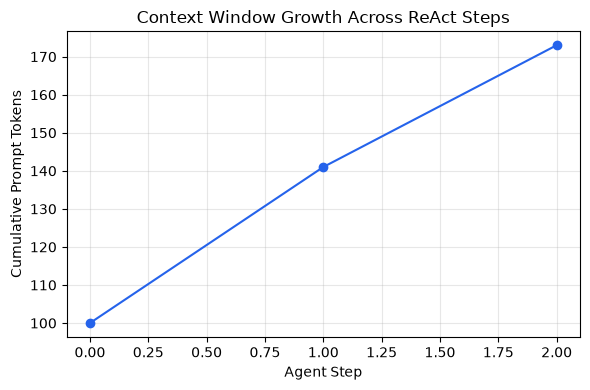

In [7]:
# ═══════════════════════════════════════════
# SECTION 1.5: Visualizing State Growth
# Theory: |s_t| = |system| + |q| + sum_{i<t}(|thought_i| + |action_i| + |observation_i|)
#   (Slide 12). Context grows monotonically because we never drop history.
# What this cell does: Recompute cumulative token count after each step and plot it.
# ═══════════════════════════════════════════

# Use build_prompt with an EMPTY history so step 0 is measured exactly the way every
# later step is measured — otherwise the baseline silently omits the 'Question: ' framing.
cumulative_tokens = [count_tokens(build_prompt('What is the population of Tokyo divided by 1000?', []))]
running_history = []
for step in range(len(trace)):
    running_history.append(trace[step])
    prompt_so_far = build_prompt('What is the population of Tokyo divided by 1000?', running_history)
    cumulative_tokens.append(count_tokens(prompt_so_far))

print('Cumulative tokens per step:', cumulative_tokens)

plt.figure(figsize=(6, 4))
plt.plot(range(len(cumulative_tokens)), cumulative_tokens, marker='o', color='#2563eb')
plt.xlabel('Agent Step')
plt.ylabel('Cumulative Prompt Tokens')
plt.title('Context Window Growth Across ReAct Steps')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# ═══════════════════════════════════════════
# SECTION 1.6: Error Handling Demo — Malformed Action Recovery
# Theory: LLMs sometimes forget the exact Action[...] syntax. A production agent must
#   catch this and feed the parse error back as an Observation rather than crashing.
# What this cell does: The "model" below is still scripted, BUT it reads the prompt before
#   answering: it emits the malformed line only while no parse error has come back yet.
#   So the correction at step 1 is genuinely CAUSED by the error observation — if the loop
#   failed to feed the error back, this mock would keep emitting the broken line forever.
#   (What is real here is the detection and recovery path: parse_action really fails, and
#   react_agent really turns that failure into an Observation.)
# ═══════════════════════════════════════════

PARSE_ERROR_MARKER = 'could not parse an Action'


def flaky_llm_response(prompt: str, step: int) -> str:
    # Not keyed by step: keyed by WHAT THE MODEL CAN SEE in its own context.
    if 'Observation: 33C' in prompt:                    # the tool already answered
        return 'Thought: Done.\nAction: finish[The weather in Bangkok is 33C, humid.]'
    if PARSE_ERROR_MARKER in prompt:                    # it was told the format was wrong
        return 'Thought: My last line was not a valid Action. Let me use the exact format.\nAction: get_weather[Bangkok]'
    return 'Thought: I will look up the weather.\nI want to call get_weather but forgot the brackets.'


answer2, trace2 = react_agent('What is the weather in Bangkok?', TOOLS, llm_generate=flaky_llm_response)
print('FINAL ANSWER:', answer2)
print('\nStep 0 was malformed; the loop turned that into an Observation, and THAT observation is')
print('what makes this mock produce a valid Action at step 1 — remove the feedback and it loops forever.')

# Proof that the recovery is causal, not scripted: run the same mock with the error feedback
# suppressed (the model never learns it failed) and watch it never recover.
print('\n--- Control: same model, but the parse error is NOT fed back ---')
_blind = react_agent('What is the weather in Bangkok?', TOOLS,
                    llm_generate=lambda prompt, step: flaky_llm_response('', step),
                    max_steps=3, verbose=False)
print('Result without feedback:', _blind[0])


--- Step 0 ---
Thought: I will look up the weather.
I want to call get_weather but forgot the brackets.
Observation: Error: could not parse an Action. Format must be 'Action: name[argument]'.

--- Step 1 ---
Thought: My last line was not a valid Action. Let me use the exact format.
Action: get_weather[Bangkok]
Observation: 33C, humid

--- Step 2 (FINAL) ---
Thought: Done.
Action: finish[The weather in Bangkok is 33C, humid.]

FINAL ANSWER: The weather in Bangkok is 33C, humid.

Step 0 was malformed; the loop turned that into an Observation, and THAT observation is
what makes this mock produce a valid Action at step 1 — remove the feedback and it loops forever.

--- Control: same model, but the parse error is NOT fed back ---
Result without feedback: Max steps reached — agent failed.


## Section 2 — Grammar-Constrained Decoding

We now switch to a real model. The core idea (Slide 21): before softmax, set the logits of every token that would break the target grammar to $-\infty$. $e^{-\infty} = 0$, so invalid tokens get exactly zero probability — masking is a hard constraint, not a soft nudge.


In [9]:
# ═══════════════════════════════════════════
# SECTION 2.1: Load a Real Causal LM
# Theory: Logit masking only makes sense on real logits from a real vocabulary — the
#   ReAct mock in Section 1 skipped this on purpose to keep that section fast and deterministic.
# What this cell does: Load distilgpt2 (82M params, small enough to run quickly on CPU).
# ═══════════════════════════════════════════

from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = 'distilgpt2'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
model.eval()

VOCAB_SIZE = model.config.vocab_size
print(f'Model: {MODEL_NAME}')
print(f'Vocab size: {VOCAB_SIZE}')
print(f'Device: {device}')


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Model: distilgpt2
Vocab size: 50257
Device: mps


In [10]:
# ═══════════════════════════════════════════
# SECTION 2.2: Unconstrained Generation — Watching It Fail
# Theory: Nothing in an LLM's training forces valid JSON. It is just predicting the
#   most likely next token, which is often "helpful chatter" rather than a closing brace.
# What this cell does: Prompt distilgpt2 to emit a JSON object and show the raw (often broken) output.
# ═══════════════════════════════════════════

prompt = 'Here is the user profile in JSON format:\n{"name": "'
enc = tokenizer(prompt, return_tensors='pt').to(device)   # input_ids + attention_mask
input_ids = enc.input_ids
print(f'input_ids shape: {input_ids.shape}')  # Expected: [1, prompt_len]

with torch.no_grad():
    generated = model.generate(
        **enc,
        max_new_tokens=30,
        do_sample=True,
        temperature=0.9,
        top_k=50,
        pad_token_id=tokenizer.eos_token_id,
    )

raw_text = tokenizer.decode(generated[0], skip_special_tokens=True)
print('--- RAW UNCONSTRAINED OUTPUT ---')
print(raw_text)
print('\ndistilgpt2 is small and undertrained for JSON, so this routinely breaks format — that is the point.')


input_ids shape: torch.Size([1, 14])


--- RAW UNCONSTRAINED OUTPUT ---
Here is the user profile in JSON format:
{"name": "Mike McCready," "text": "Mike McCready", "text": "Mike McCready," "text": "Mike McCready," "text

distilgpt2 is small and undertrained for JSON, so this routinely breaks format — that is the point.


In [11]:
# ═══════════════════════════════════════════
# SECTION 2.3: Logit-Level Masking
# Theory: logit'_i = logit_i if i in V_valid else -inf  (Slide 21).
#   After softmax, e^(-inf) = 0, so masked tokens are mathematically unreachable.
# What this cell does: Defines apply_token_mask(logits, allowed_token_ids).
# ═══════════════════════════════════════════


def apply_token_mask(logits: torch.Tensor, allowed_token_ids: list) -> torch.Tensor:
    # logits: [batch, vocab_size]. Returns a new tensor of the same shape.
    # NOTE: no print in here -- this function runs once per decoding step, so a print
    # would flood the output in Section 2.7. Shapes are printed by the callers instead.
    mask = torch.full_like(logits, float('-inf'))
    mask[:, allowed_token_ids] = 0.0
    return logits + mask


# Sanity check on a tiny fake example
fake_logits = torch.tensor([[1.0, 2.0, 3.0, 0.5]])
masked = apply_token_mask(fake_logits, allowed_token_ids=[1, 3])
print('Fake logits before:', fake_logits)
print('Fake logits after: ', masked)
print('Probabilities after softmax:', F.softmax(masked, dim=-1))


Fake logits before: tensor([[1.0000, 2.0000, 3.0000, 0.5000]])
Fake logits after:  tensor([[  -inf, 2.0000,   -inf, 0.5000]])
Probabilities after softmax: tensor([[0.0000, 0.8176, 0.0000, 0.1824]])


In [12]:
# ═══════════════════════════════════════════
# SECTION 2.4: Forcing a Quote After `{`
# Theory: After optional whitespace, a JSON object parser allows `"` (start a key) or
#   `}` (empty object). We use .strip() below so tokens carrying leading whitespace
#   (e.g. ' "') count as valid — that matches what the JSON grammar actually permits.
#   This is the state used on Slide 22: structural positions constrain hard.
# What this cell does: Compute distilgpt2's next-token logits after `{`, then mask
#   everything except tokens that start with `"` or are `}`.
# ═══════════════════════════════════════════

prompt = 'Here is the JSON:\n{'
input_ids = tokenizer(prompt, return_tensors='pt').input_ids.to(device)
with torch.no_grad():
    logits = model(input_ids).logits[:, -1, :]  # [1, vocab_size] — logits for the NEXT token only
print(f'next-token logits shape: {logits.shape}')

# A token is a valid continuation iff `'{' + piece` is still a viable PREFIX of some
# complete JSON document. Note this is genuinely a parser question, not a string-prefix
# question — the tempting one-liner
#       piece.strip().startswith('"') or piece.strip() == '}'
# is WRONG in both directions: it drops whitespace-only tokens like '\n' (JSON allows
# whitespace after '{'), and it admits tokens like '"""' which open a key, close it, and
# then emit a quote where a colon is required. On GPT-2 both rules happen to return 69,
# but they are different sets of 69 — a good reminder to test the property, not the count.
# Scope: this helper only handles the ONE parser state on Slide 22 (right after `{`). It does not
# validate escape sequences (a key containing \q is accepted) and does not follow the grammar past
# the colon (the valid prefix `{"x":1` is rejected), so it is not a general JSON-prefix validator.
# The 69-token count is for GPT-2's tokenizer in this state only.
def viable_after_open_brace(piece: str) -> bool:
    t = piece.lstrip(' \t\n\r')
    if t == '':
        return True                      # whitespace only — still waiting for the key
    if t == '}':
        return True                      # empty object
    if not t.startswith('"'):
        return False                     # a key must start here
    rest, i = t[1:], 0                   # walk the key string; it may stay open
    while i < len(rest):
        c = rest[i]
        if c == '\\':
            i += 2                        # escape consumes the next char
            continue
        if c == '"':                     # key closed — only ':' may follow
            return rest[i + 1:].lstrip(' \t\n\r') in ('', ':')
        if ord(c) < 0x20:
            return False                 # raw control char is illegal inside a string
        i += 1
    return True                          # key still open — fine


valid_ids = [t for t in range(VOCAB_SIZE) if viable_after_open_brace(tokenizer.decode([t]))]
print(f'Valid tokens found: {len(valid_ids)} out of {VOCAB_SIZE}')

top5_before = torch.topk(logits, 5)
print('\nTop-5 BEFORE masking:')
for score, idx in zip(top5_before.values[0], top5_before.indices[0]):
    print(f'  {tokenizer.decode([idx.item()])!r:15s} logit={score.item():.3f}')

masked_logits = apply_token_mask(logits, valid_ids)
top5_after = torch.topk(masked_logits, 5)
print('\nTop-5 AFTER masking (only tokens that keep the JSON parseable survive —\n'
      "note '\\n' survives: JSON allows whitespace after '{'):")
for score, idx in zip(top5_after.values[0], top5_after.indices[0]):
    print(f'  {tokenizer.decode([idx.item()])!r:15s} logit={score.item():.3f}')

# The real punchline of Slide 21: how much probability mass sat on VALID tokens before
# vs after. Top-5 barely moves here (the model already wanted a quote), but the mass does.
mass_before = F.softmax(logits, dim=-1)[0, valid_ids].sum().item()
mass_after = F.softmax(masked_logits, dim=-1)[0, valid_ids].sum().item()
print(f'\nP(valid token) BEFORE masking: {mass_before:.4f}  '
      f'-> the model had a {100*(1-mass_before):.1f}% chance of emitting something illegal')
print(f'P(valid token) AFTER  masking: {mass_after:.4f}  '
      f'-> illegal tokens are now unreachable, not merely unlikely')


next-token logits shape: torch.Size([1, 50257])
Valid tokens found: 69 out of 50257

Top-5 BEFORE masking:
  ' "'            logit=-37.582
  '\n'            logit=-39.646
  ' //'           logit=-40.078
  ' name'         logit=-40.425
  " '"            logit=-40.889

Top-5 AFTER masking (only tokens that keep the JSON parseable survive —
note '\n' survives: JSON allows whitespace after '{'):
  ' "'            logit=-37.582
  '\n'            logit=-39.646
  ' "_'           logit=-41.993
  ' }'            logit=-42.008
  ' "@'           logit=-42.484

P(valid token) BEFORE masking: 0.4020  -> the model had a 59.8% chance of emitting something illegal
P(valid token) AFTER  masking: 1.0000  -> illegal tokens are now unreachable, not merely unlikely


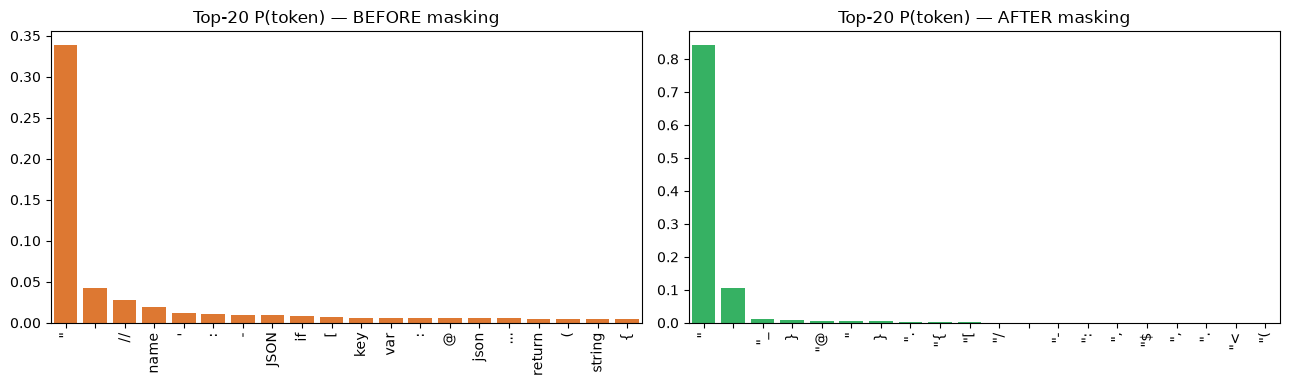

In [13]:
# ═══════════════════════════════════════════
# SECTION 2.5: Visualizing Before vs. After
# What this cell does: Bar chart of top-20 token probabilities before/after masking.
# ═══════════════════════════════════════════

probs_before = F.softmax(logits, dim=-1)[0]
probs_after = F.softmax(masked_logits, dim=-1)[0]

top20_before = torch.topk(probs_before, 20)
labels_before = [tokenizer.decode([i.item()]) for i in top20_before.indices]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(x=np.arange(20), y=top20_before.values.detach().cpu().numpy(), ax=axes[0], color='#f97316')
axes[0].set_title('Top-20 P(token) — BEFORE masking')
axes[0].set_xticks(range(20))
axes[0].set_xticklabels(labels_before, rotation=90)

top20_after = torch.topk(probs_after, 20)
labels_after = [tokenizer.decode([i.item()]) for i in top20_after.indices]
sns.barplot(x=np.arange(20), y=top20_after.values.detach().cpu().numpy(), ax=axes[1], color='#22c55e')
axes[1].set_title('Top-20 P(token) — AFTER masking')
axes[1].set_xticks(range(20))
axes[1].set_xticklabels(labels_after, rotation=90)

plt.tight_layout()
plt.show()


In [14]:
# ═══════════════════════════════════════════
# SECTION 2.6: Regex-Constrained Decoding — Forcing YYYY-MM-DD
# Theory: A regex compiles to a DFA. At each DFA state, only a handful of characters
#   are valid transitions (Slide 25).
# What this cell does: (1) compile the regex source into its chain of DFA transition labels,
#   (2) index each state's character class against the vocabulary once,
#   (3) decode 10 steps by hand, masking to that state's token ids.
# Scope: our compiler handles concatenation of atoms with fixed repeat counts, which is
#   all a flat field pattern needs and makes the DFA a simple chain. Branching (|) and
#   loops (*, +) need a real engine — that is what `outlines` provides.
# ═══════════════════════════════════════════

DATE_REGEX = r'\d{4}-\d{2}-\d{2}'


def compile_regex_to_state_chain(pattern: str) -> list:
    """Expand a regex source into one character class per DFA transition (the label on each arrow)."""
    chain = []
    for atom, repeat in re.findall(r'(\\d|.)(?:\{(\d+)\})?', pattern):
        chain.extend([atom] * int(repeat or 1))
    return chain


DATE_STEP_CLASSES = compile_regex_to_state_chain(DATE_REGEX)
print('Regex     :', DATE_REGEX)
print('Transition labels (allowed chars per step):', DATE_STEP_CLASSES, f'({len(DATE_STEP_CLASSES)} transitions)')

_CHAR_CLASS_CACHE = {}


def char_class_to_token_ids(char_class: str) -> list:
    """Index the vocabulary once per character class (Willard & Louf's precomputed index)."""
    if char_class in _CHAR_CLASS_CACHE:
        return _CHAR_CLASS_CACHE[char_class]
    valid = [tid for tid in range(VOCAB_SIZE)
             if re.fullmatch(char_class, tokenizer.decode([tid]))]
    _CHAR_CLASS_CACHE[char_class] = valid
    return valid


prompt = 'The invoice date is '
generated_ids = tokenizer(prompt, return_tensors='pt').input_ids.to(device)

for step, char_class in enumerate(DATE_STEP_CLASSES):
    with torch.no_grad():
        logits = model(generated_ids).logits[:, -1, :]
    valid_ids = char_class_to_token_ids(char_class)
    masked_logits = apply_token_mask(logits, valid_ids)
    next_id = torch.argmax(masked_logits, dim=-1, keepdim=True)
    generated_ids = torch.cat([generated_ids, next_id], dim=1)

print('Index built for', {k: len(v) for k, v in _CHAR_CLASS_CACHE.items()},
      f'— {len(_CHAR_CLASS_CACHE)} vocabulary scans for {len(DATE_STEP_CLASSES)} steps')

date_str = tokenizer.decode(generated_ids[0, -10:])
print('Forced output:', tokenizer.decode(generated_ids[0]))
print('Extracted date field:', date_str)
assert re.fullmatch(DATE_REGEX, date_str), 'Masking failed to produce a valid date!'
print('Format is guaranteed valid — masking made it impossible to be otherwise.')
print('...but look at the value: argmax on a tiny model gives an arbitrary date (1111-11-11 happens to be\n'
      '   a real date). Section 2.7 samples dates such as 3194-81-59: masking guarantees SYNTAX, not\n'
      '   semantics — schema/business validation is still a separate layer (Slide 26).')


Regex     : \d{4}-\d{2}-\d{2}
Transition labels (allowed chars per step): ['\\d', '\\d', '\\d', '\\d', '-', '\\d', '\\d', '-', '\\d', '\\d'] (10 transitions)


Index built for {'\\d': 10, '-': 1} — 2 vocabulary scans for 10 steps
Forced output: The invoice date is 1111-11-11
Extracted date field: 1111-11-11
Format is guaranteed valid — masking made it impossible to be otherwise.
...but look at the value: argmax on a tiny model gives an arbitrary date (1111-11-11 happens to be
   a real date). Section 2.7 samples dates such as 3194-81-59: masking guarantees SYNTAX, not
   semantics — schema/business validation is still a separate layer (Slide 26).


Prompt: 'The invoice date is '

Unconstrained (first 5 of 20):
  invalid  '\xa0 2014.\xa0<|endoftext|>'
  invalid  '!!! _______________________________________________________________________\nYou may enter a description'
  invalid  '!!!!!!!!!!!! LOL!! villainous b.h'
  invalid  '【$1] - 8\n\n\n\n'
  invalid  'urn:2008/09/28<|endoftext|>'

Constrained (first 5 of 20):
  valid    '3194-81-59'
  valid    '8932-31-51'
  valid    '1584-22-28'
  valid    '0230-48-12'
  valid    '4122-68-68'

Unconstrained compliance: 0/20 = 0%
Constrained compliance:   20/20 = 100%


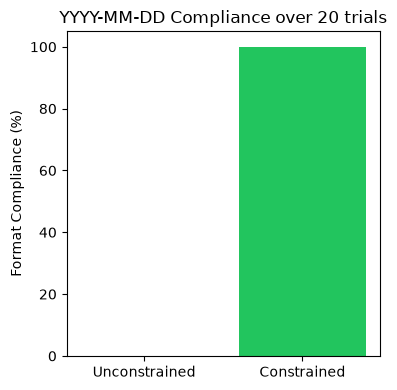

In [15]:
# ═══════════════════════════════════════════
# SECTION 2.7: Benchmark — Unconstrained vs. Constrained Compliance Rate
# What this cell does: Generate the date field N_TRIALS times each way, print a few of the
#   raw outputs from each side, then measure the valid-format rate.
# ═══════════════════════════════════════════

N_TRIALS = 20


def unconstrained_date_attempt():
    enc = tokenizer(prompt, return_tensors='pt').to(device)
    ids = enc.input_ids
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=10, do_sample=True, temperature=1.0,
                              top_k=50, pad_token_id=tokenizer.eos_token_id)
    tail = tokenizer.decode(out[0, ids.shape[1]:])
    return tail


def constrained_date_attempt():
    ids = tokenizer(prompt, return_tensors='pt').input_ids.to(device)
    for char_class in DATE_STEP_CLASSES:
        with torch.no_grad():
            step_logits = model(ids).logits[:, -1, :]
        valid_ids = char_class_to_token_ids(char_class)
        masked_step_logits = apply_token_mask(step_logits, valid_ids)
        probs = F.softmax(masked_step_logits, dim=-1)
        next_id = torch.multinomial(probs, num_samples=1)
        ids = torch.cat([ids, next_id], dim=1)
    return tokenizer.decode(ids[0, -10:])


DATE_PATTERN = re.compile(DATE_REGEX)
# Note the asymmetry is in the UNCONSTRAINED method's favour: .search() accepts a date anywhere
# in the 10-token tail, while the constrained output must .fullmatch(). It still loses.

unconstrained_outputs = [unconstrained_date_attempt() for _ in range(N_TRIALS)]
constrained_outputs = [constrained_date_attempt() for _ in range(N_TRIALS)]
unconstrained_hits = sum(1 for t in unconstrained_outputs if DATE_PATTERN.search(t))
constrained_hits = sum(1 for t in constrained_outputs if DATE_PATTERN.fullmatch(t))

# Show what the model actually wrote, not just the rate.
N_SHOW = 5
print(f'Prompt: {prompt!r}\n')
print(f'Unconstrained (first {N_SHOW} of {N_TRIALS}):')
for t in unconstrained_outputs[:N_SHOW]:
    print(f"  {'valid  ' if DATE_PATTERN.search(t) else 'invalid'}  {t!r}")
print(f'\nConstrained (first {N_SHOW} of {N_TRIALS}):')
for t in constrained_outputs[:N_SHOW]:
    print(f"  {'valid  ' if DATE_PATTERN.fullmatch(t) else 'invalid'}  {t!r}")
print()

print(f'Unconstrained compliance: {unconstrained_hits}/{N_TRIALS} = {100*unconstrained_hits/N_TRIALS:.0f}%')
print(f'Constrained compliance:   {constrained_hits}/{N_TRIALS} = {100*constrained_hits/N_TRIALS:.0f}%')

plt.figure(figsize=(4, 4))
plt.bar(['Unconstrained', 'Constrained'], [100 * unconstrained_hits / N_TRIALS, 100 * constrained_hits / N_TRIALS],
        color=['#f97316', '#22c55e'])
plt.ylabel('Format Compliance (%)')
plt.ylim(0, 105)
plt.title(f'YYYY-MM-DD Compliance over {N_TRIALS} trials')
plt.tight_layout()
plt.show()


## Section 3 — Memory Management Architectures

Three ways to keep an agent's *prompt* from growing without bound as the conversation does (Slide 31): Buffer (does not bound it — the baseline), Summary, and Retrieval. The ingestion-time vs. runtime split from Slide 29 is the same idea one level up: pre-digest, then load only what is relevant.


In [16]:
# ═══════════════════════════════════════════
# SECTION 3.1: Buffer Memory — O(n) Growth
# Theory: Simplest possible memory. Append everything, forget nothing. Context grows
#   linearly with turn count (Slide 31) until it overflows the window.
# What this cell does: Implements BufferMemory.
# ═══════════════════════════════════════════


class BufferMemory:
    def __init__(self):
        self.turns = []

    def add(self, role: str, text: str):
        self.turns.append((role, text))

    def get_context(self) -> str:
        return '\n'.join(f'{role}: {text}' for role, text in self.turns)

    def token_count(self) -> int:
        return count_tokens(self.get_context())


bm = BufferMemory()
bm.add('user', 'Hello, what is the capital of Thailand?')
bm.add('assistant', 'The capital of Thailand is Bangkok.')
print(bm.get_context())
print('Tokens:', bm.token_count())


user: Hello, what is the capital of Thailand?
assistant: The capital of Thailand is Bangkok.
Tokens: 20


In [17]:
# ═══════════════════════════════════════════
# SECTION 3.2: Summary Memory — Bounded via Periodic Compression
# Theory: When the buffer exceeds max_tokens, collapse the oldest turns into one summary
#   string. Context becomes O(keep_recent * turn_len + |summary|) instead of O(n) (Slide 31).
# HONEST CAVEATS (say these out loud — "bounded" is doing a lot of work):
#   1. Bounded only if |summary| is capped. We cap it by re-summarizing from running
#      totals AND capping the topic set — see MAX_TOPICS below. Let the topic set grow
#      forever and the "summary" grows with it, just more slowly than Buffer.
#   2. max_tokens is a trigger, not a hard ceiling: the keep_recent most recent turns are
#      never compressed, so one huge message can sit above budget indefinitely.
#   3. This is lossy by construction — we keep topic words and a count, nothing else.
# What this cell does: Implements SummaryMemory with a mock summarizer.
# ═══════════════════════════════════════════


MAX_TOPICS = 20  # hard cap: without this, `topics` grows with the conversation forever


def topic_word(text: str) -> str:
    # Keep a keyword, not the first word: the first word of every turn is "Question" or
    # "Answer", which would tell us nothing about what was folded into the summary.
    m = re.search(r"\b(topic\w+|subject_\w+)", text)
    return m.group(1) if m else None


def mock_summarize(n_turns: int, topics: set) -> str:
    # Stand-in for an LLM call that RE-summarizes everything seen so far into ONE sentence.
    # Deterministic and fast so the demo does not need a real summarization model.
    # Critical: it takes the running totals, not the old summary string, so the result
    # has a FIXED length no matter how many turns have been folded in.
    return f"[Summary of {n_turns} earlier turns, topics: {', '.join(sorted(topics)[:5])}...]"


class SummaryMemory:
    def __init__(self, max_tokens: int = 200, keep_recent: int = 2):
        self.turns = []
        self.summary = None
        self.max_tokens = max_tokens
        self.keep_recent = keep_recent
        self.n_summarized = 0   # running total, so the summary can be rewritten not appended
        self.topics = set()

    def add(self, role: str, text: str):
        self.turns.append((role, text))
        if self.token_count() > self.max_tokens:
            self._compress()

    def _compress(self):
        if len(self.turns) <= self.keep_recent:
            return
        to_summarize = self.turns[:-self.keep_recent]
        # Fold the old turns into the RUNNING TOTALS, then rewrite the summary from scratch.
        # Appending (`self.summary + new_text`) would make the summary itself grow without
        # bound -- the memory would be O(n) again, defeating the whole point.
        self.n_summarized += len(to_summarize)
        # Cap the topic set so `self.topics` cannot grow without bound over a long session.
        for _, text in to_summarize:
            word = topic_word(text)
            if word and len(self.topics) < MAX_TOPICS:
                self.topics.add(word)
        self.summary = mock_summarize(self.n_summarized, self.topics)
        self.turns = self.turns[-self.keep_recent:]

    def get_context(self) -> str:
        parts = []
        if self.summary:
            parts.append(f'Summary: {self.summary}')
        parts.extend(f'{role}: {text}' for role, text in self.turns)
        return '\n'.join(parts)

    def token_count(self) -> int:
        return count_tokens(self.get_context())


sm = SummaryMemory(max_tokens=60, keep_recent=2)
for i in range(6):
    sm.add('user', f'Question number {i} about topic{i}')
    sm.add('assistant', f'Answer number {i} with some detail padding text here')
print(sm.get_context())
print('Tokens:', sm.token_count())


Summary: [Summary of 10 earlier turns, topics: topic0, topic1, topic2, topic3, topic4...]
user: Question number 5 about topic5
assistant: Answer number 5 with some detail padding text here
Tokens: 50


In [18]:
# ═══════════════════════════════════════════
# SECTION 3.3: Retrieval Memory — Bounded via Semantic Search
# Theory: Instead of summarizing, embed every past turn and retrieve only the top-k
#   most relevant ones for the CURRENT query. Context stays O(k) regardless of history
#   length — this is RAG (Week 12) applied to an agent's own conversation history.
# NOTE ON THE SLIDE: Slide 31 says "embed + vector-search". Here we use TF-IDF + cosine
#   instead of a dense sentence encoder, purely so the notebook runs instantly with no
#   model download. The retrieval mechanism — score every turn, keep top-k — is identical;
#   swapping in SBERT from Week 9 would change the scores, not the architecture.
# What this cell does: Implements RetrievalMemory using TF-IDF + cosine similarity.
# ═══════════════════════════════════════════

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


class RetrievalMemory:
    def __init__(self, top_k: int = 2):
        self.turns = []  # list of (role, text)
        self.top_k = top_k

    def add(self, role: str, text: str):
        self.turns.append((role, text))

    def get_context(self, query: str) -> str:
        if len(self.turns) <= self.top_k:
            relevant = self.turns
        else:
            corpus = [text for _, text in self.turns]
            vectorizer = TfidfVectorizer().fit(corpus + [query])
            turn_vecs = vectorizer.transform(corpus)
            query_vec = vectorizer.transform([query])
            sims = cosine_similarity(query_vec, turn_vecs)[0]  # shape: [n_turns]
            top_idx = np.argsort(sims)[-self.top_k:]
            relevant = [self.turns[i] for i in sorted(top_idx)]
        return '\n'.join(f'{role}: {text}' for role, text in relevant)

    def token_count(self, query: str) -> int:
        return count_tokens(self.get_context(query))


rm = RetrievalMemory(top_k=2)
for i in range(6):
    rm.add('user', f'Question number {i} about topic{i}')
    rm.add('assistant', f'Answer number {i} with some detail padding text here')
print(rm.get_context('Tell me about topic3'))
# Note: the second hit (topic5) is retrieved only because TF-IDF matches the word "about".
# This is the "may miss or mis-rank" weakness from Slide 31; TfidfVectorizer(stop_words='english')
# or a dense encoder would reduce it.
print('Tokens:', rm.token_count('Tell me about topic3'))


user: Question number 3 about topic3
user: Question number 5 about topic5
Tokens: 19


In [19]:
# ═══════════════════════════════════════════
# SECTION 3.4: Side-by-Side Simulation — 20-Turn Conversation
# What this cell does: Run the same synthetic 20-turn conversation through all three
#   memories and collect the token usage after every turn.
# ═══════════════════════════════════════════


def synthetic_turn(i: int) -> tuple:
    user_msg = f'Can you explain concept number {i} about subject_{i % 5} in some detail please?'
    assistant_msg = f'Concept {i} about subject_{i % 5} works as follows: it involves several padding words to simulate a longer real answer from the model.'
    return user_msg, assistant_msg


buffer_mem = BufferMemory()
summary_mem = SummaryMemory(max_tokens=200, keep_recent=3)  # trigger above the steady-state size, so the sawtooth is visible
retrieval_mem = RetrievalMemory(top_k=3)

buffer_tokens, summary_tokens, retrieval_tokens = [], [], []
final_query = 'Remind me about subject_2'

for i in range(20):
    u, a = synthetic_turn(i)
    buffer_mem.add('user', u)
    buffer_mem.add('assistant', a)
    summary_mem.add('user', u)
    summary_mem.add('assistant', a)
    retrieval_mem.add('user', u)
    retrieval_mem.add('assistant', a)

    buffer_tokens.append(buffer_mem.token_count())
    summary_tokens.append(summary_mem.token_count())
    retrieval_tokens.append(retrieval_mem.token_count(final_query))

print('Buffer tokens (last 5):   ', buffer_tokens[-5:])
print('Summary tokens (last 5):  ', summary_tokens[-5:])
print('Retrieval tokens (last 5):', retrieval_tokens[-5:])


Buffer tokens (last 5):    [736, 782, 828, 874, 920]
Summary tokens (last 5):   [171, 107, 153, 199, 125]
Retrieval tokens (last 5): [54, 54, 54, 54, 54]


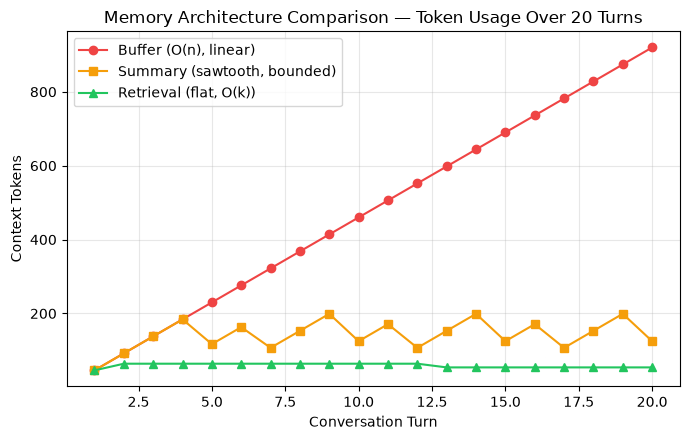

In [20]:
# ═══════════════════════════════════════════
# SECTION 3.5: Visualization — Token Usage vs. Turn
# What this cell does: Line plot comparing the three growth curves.
# ═══════════════════════════════════════════

plt.figure(figsize=(7, 4.5))
plt.plot(range(1, 21), buffer_tokens, marker='o', label='Buffer (O(n), linear)', color='#ef4444')
plt.plot(range(1, 21), summary_tokens, marker='s', label='Summary (sawtooth, bounded)', color='#f59e0b')
plt.plot(range(1, 21), retrieval_tokens, marker='^', label='Retrieval (flat, O(k))', color='#22c55e')
plt.xlabel('Conversation Turn')
plt.ylabel('Context Tokens')
plt.title('Memory Architecture Comparison — Token Usage Over 20 Turns')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Section 4 — Two Multi-Agent Topologies in Miniature

Everything here is mock LLMs and plain Python — the point is the *wiring*, not the model. Section 4.1 is the Sequential Pipeline of Slides 34–35 (with the error cascade); Section 4.2 is the Routing Network of Slides 36–37 (with a misroute).


In [21]:
# ═══════════════════════════════════════════
# SECTION 4.1: Sequential Pipeline — Research → Writer → Editor, and the Error Cascade
# Theory: y_i = f_i(y_{i-1}) (Slide 34). Each "agent" is a function with its own prompt and tools;
#   the output of one is the whole input of the next. Nothing downstream can see the original
#   question or re-check facts — so an upstream miss propagates unchanged (Slide 35).
# What this cell does: Three mock agents composed as Editor(Writer(Research(topic))), run once on a
#   topic the research tool knows and once on a topic it does not.
# ═══════════════════════════════════════════


def research_agent(topic: str) -> list:
    # Tools: search_wikipedia (from Section 1.1). Output: a list of "facts" (strings).
    result = search_wikipedia(topic)
    return [result]                      # a real agent would run several searches and filter


def writer_agent(facts: list) -> str:
    # No tools. Turns whatever facts it is handed into prose — it cannot tell a fact from an error string.
    body = ' '.join(facts)
    return f'Did you know? {body} This makes it one of the most interesting statistics in the region.'


def editor_agent(draft: str) -> str:
    # Tool: a "dictionary" (here: a tiny style rule). Polishes wording; never checks facts.
    return draft.replace('approximately', 'about').replace('Did you know?', 'Fun fact:')


def blog_pipeline(topic: str) -> str:
    return editor_agent(writer_agent(research_agent(topic)))   # Editor(Writer(Research(q)))


for topic in ['population of Bangkok', 'population of Chiang Mai']:
    print(f'--- topic: {topic!r}')
    print('  Research ->', research_agent(topic))
    print('  Final    ->', blog_pipeline(topic))
    print()

print('Second run: Research missed, Writer wrote fluent prose AROUND the error string, Editor polished it.')
print('Nobody downstream could detect the miss — that is the error cascade of Slide 34.')


--- topic: 'population of Bangkok'
  Research -> ['Bangkok has a population of approximately 10,700,000.']
  Final    -> Fun fact: Bangkok has a population of about 10,700,000. This makes it one of the most interesting statistics in the region.

--- topic: 'population of Chiang Mai'
  Research -> ["No article found for 'population of Chiang Mai'."]
  Final    -> Fun fact: No article found for 'population of Chiang Mai'. This makes it one of the most interesting statistics in the region.

Second run: Research missed, Writer wrote fluent prose AROUND the error string, Editor polished it.
Nobody downstream could detect the miss — that is the error cascade of Slide 34.


In [22]:
# ═══════════════════════════════════════════
# SECTION 4.2: Routing Network — a Rule-Based Dispatcher and a Misroute
# Theory: r(q) -> agent_k (Slide 37). The router runs once, then exactly one specialist handles
#   the query. Cheap and fast — but the specialist never sees the alternatives, so a wrong
#   routing decision is unrecoverable (Slide 36: single point of failure).
# What this cell does: Implements option 3 from Slide 37 (keyword rules), routes three queries,
#   and shows one whose keywords collide so the router sends it to the wrong desk.
# ═══════════════════════════════════════════


def billing_agent(q: str) -> str:
    return 'BILLING: I have pulled up your last invoice and can issue a refund.'


def tech_agent(q: str) -> str:
    return 'TECH: Let us restart the router and check your connection logs.'


def sales_agent(q: str) -> str:
    return 'SALES: Our premium plan includes unlimited bandwidth — shall I upgrade you?'


SPECIALISTS = {'billing': billing_agent, 'tech': tech_agent, 'sales': sales_agent}
ROUTING_RULES = {          # option 3 on Slide 37: keyword matching, FIRST rule that hits wins
    'sales':   ['upgrade', 'plan', 'price', 'premium'],
    'tech':    ['connection', 'error', 'not working', 'restart'],
    'billing': ['invoice', 'refund', 'charged', 'payment'],
}


def route(query: str) -> str:
    q = query.lower()
    for agent_name, keywords in ROUTING_RULES.items():
        if any(k in q for k in keywords):
            return agent_name
    return 'tech'            # default desk


QUERIES = [
    'I was charged twice this month, please refund one payment.',
    'My connection drops every evening and the app shows an error.',
    'I want to cancel my premium plan because I was charged after cancelling.',   # keywords collide
]
for q in QUERIES:
    k = route(q)
    print(f'{q}\n  -> routed to {k:8s} -> {SPECIALISTS[k](q)}\n')

print('Query 3 is a billing dispute, but "premium plan" matched the sales rule, which is checked first, so')
print('the router sent it to the wrong desk — and the specialist cheerfully answered the wrong question.')
print('Routing accuracy is the whole game (Slide 37); an LLM or embedding router trades speed for that.')


I was charged twice this month, please refund one payment.
  -> routed to billing  -> BILLING: I have pulled up your last invoice and can issue a refund.

My connection drops every evening and the app shows an error.
  -> routed to tech     -> TECH: Let us restart the router and check your connection logs.

I want to cancel my premium plan because I was charged after cancelling.
  -> routed to sales    -> SALES: Our premium plan includes unlimited bandwidth — shall I upgrade you?

Query 3 is a billing dispute, but "premium plan" matched the sales rule, which is checked first, so
the router sent it to the wrong desk — and the specialist cheerfully answered the wrong question.
Routing accuracy is the whole game (Slide 37); an LLM or embedding router trades speed for that.


## Recap

- **Section 1** showed a ReAct feedback loop using a full-history augmented state; truncation can make the observation incomplete.
- **Section 2** showed that logit masking makes invalid tokens mathematically unreachable ($e^{-\infty}=0$), at the cost of ~1 extra vocabulary scan per new character class — and that it guarantees syntax only (the forced date was `1111-11-11`).
- **Section 3** showed the three-way trade-off: Buffer (simple, unbounded), Summary (bounded *prompt*, lossy, and only bounded because we cap the summary), Retrieval (bounded *prompt*, relevance-based — but the store still holds all $n$ turns and TF-IDF is refit over the whole history each query). Note what is bounded in each case is the **prompt**, not the memory itself.
- **Section 4** showed the two cheapest multi-agent topologies and their signature failure each: a pipeline turns one upstream miss into a confident wrong article (error cascade), and a router that picks the wrong specialist cannot be rescued by that specialist (single point of failure).

The lab (`week13_lab_student.ipynb`) asks you to write the one line of the ReAct loop that replays history into the prompt, then measure the context growth that line causes.
